# 01 - Preprocessing

**Objective:** Predict customer next month spend (`spend_next_month`).

Loads raw data, inspects it, extracts temporal features, cleanses missing values,
drops extreme outliers, validates the result, and saves `data/processed/cleaned.csv`.


## Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

sns.set(style="darkgrid")

BASE     = Path('.')
RAW_PATH = BASE / 'data' / 'raw'  / 'customer_spend_dataset.csv'
OUT_PATH = BASE / 'data' / 'processed' / 'cleaned.csv'


## Load Raw Data

In [2]:
df = pd.read_csv(RAW_PATH)
print(f"Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Loaded: 25,000 rows x 40 columns


,customer_id,snapshot_date,age,gender,region,education,household_size,has_children,annual_income,tenure_months,...,email_open_rate,email_click_rate,push_enabled,cart_abandon_rate,wishlist_items,support_tickets_90d,campaign_responses_6m,target_month,promo_planned_next_month,spend_next_month
0,C100000,2024-10-31,42,F,Suburban,High school,2,0,29400.0,40,...,0.205,0.032,0,0.651,4,0,0,11,0,106.67
1,C100001,2023-10-31,26,F,Urban,Master,2,0,46200.0,72,...,0.499,0.086,1,0.497,1,0,1,11,1,296.00
2,C100002,2024-02-29,47,M,Urban,Bachelor,5,0,42500.0,33,...,0.280,0.096,1,0.638,2,0,0,3,1,121.78
3,C100003,2023-08-31,49,M,Suburban,Master,3,1,64500.0,35,...,0.464,0.096,1,0.359,3,0,2,9,1,367.96
4,C100004,2024-11-30,18,M,Suburban,Bachelor,4,1,44000.0,48,...,0.573,0.241,1,0.693,2,0,1,12,0,165.40


## Initial Inspection

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 40 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               25000 non-null  object 
 1   snapshot_date             25000 non-null  object 
 2   age                       25000 non-null  int64  
 3   gender                    25000 non-null  object 
 4   region                    25000 non-null  object 
 5   education                 24034 non-null  object 
 6   household_size            25000 non-null  int64  
 7   has_children              25000 non-null  int64  
 8   annual_income             23441 non-null  float64
 9   tenure_months             25000 non-null  int64  
 10  membership_tier           25000 non-null  object 
 11  preferred_channel         25000 non-null  object 
 12  loyalty_points            25000 non-null  int64  
 13  spend_last_1m             25000 non-null  float64
 14  spend_

In [4]:
df.shape

(25000, 40)

In [5]:
df.nunique().to_frame(name='Unique values')

,Unique values
customer_id,25000
snapshot_date,18
age,63
gender,3
region,3
education,4
household_size,6
has_children,2
annual_income,1066
tenure_months,120


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,25000.0,38.335040,11.535897,18.000,30.0000,38.000,46.0000,80.000
household_size,25000.0,2.593720,1.237707,1.000,2.0000,2.000,3.0000,6.000
has_children,25000.0,0.359440,0.479846,0.000,0.0000,0.000,1.0000,1.000
annual_income,23441.0,45701.160360,18358.107555,12000.000,32700.0000,42500.000,55200.0000,198200.000
tenure_months,25000.0,30.849240,20.558056,1.000,16.0000,26.000,41.0000,120.000
loyalty_points,25000.0,2445.007040,2796.207512,73.000,897.0000,1545.500,2860.0000,46342.000
spend_last_1m,25000.0,331.601051,361.907252,0.000,111.2275,223.725,421.1025,5972.670
spend_prev_2m,25000.0,326.742825,349.132795,0.000,113.9125,222.985,414.0475,5382.310
avg_spend_3m,25000.0,327.666729,332.349586,0.000,125.4150,227.030,409.2925,4844.780
avg_spend_6m,25000.0,326.412074,322.324411,3.730,129.7875,229.735,407.2850,4698.300


In [7]:
df.describe(include='O')

,customer_id,snapshot_date,gender,region,education,membership_tier,preferred_channel
count,25000,25000,25000,25000,24034,25000,25000
unique,25000,18,3,3,4,3,3
top,C100000,2023-08-31,F,Urban,Bachelor,Basic,App
freq,1,1439,12378,11973,10813,12612,9420


## Missing Values

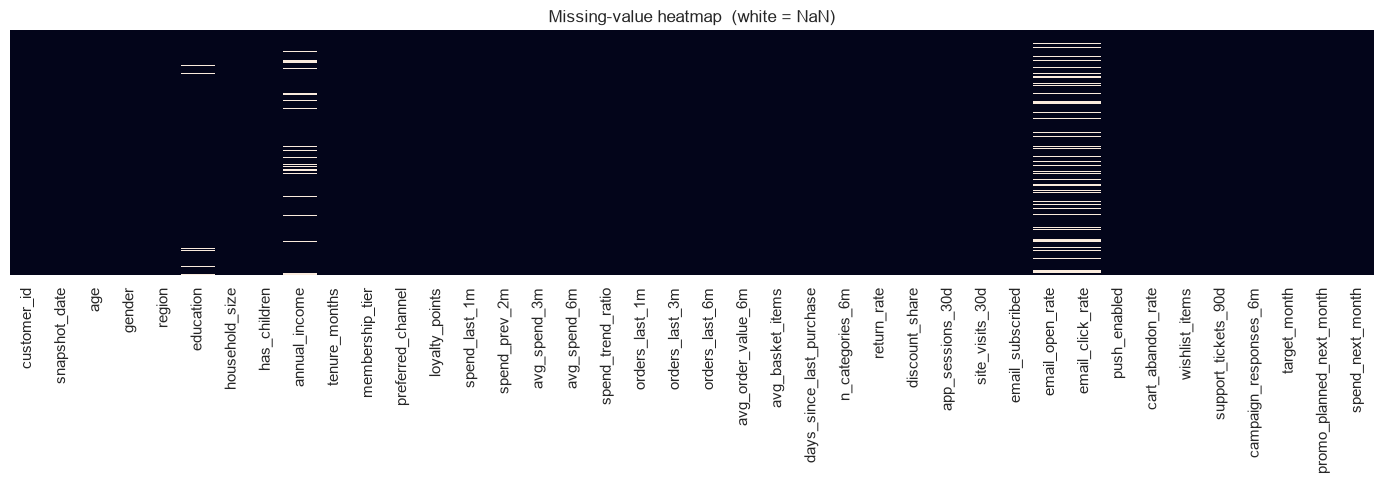

email_open_rate      5539
email_click_rate     5539
annual_income        1559
education             966
spend_trend_ratio       6

Total missing cells : 13,609  (1.36% of data)


In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(df.isnull(), cbar=False, ax=ax, yticklabels=False)
ax.set_title('Missing-value heatmap  (white = NaN)')
plt.tight_layout()
plt.show()

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing.to_string())
print(f"\nTotal missing cells : {df.isnull().sum().sum():,}  "
      f"({df.isnull().sum().sum() / df.size * 100:.2f}% of data)")


## Extract Temporal Features from `snapshot_date`

`snapshot_date` encodes the month and year of each snapshot.
We extract month, quarter and year as numeric features before dropping the raw column.


In [9]:
df['snapshot_date'] = pd.to_datetime(df['snapshot_date'])

df['snapshot_month']   = df['snapshot_date'].dt.month
df['snapshot_quarter'] = df['snapshot_date'].dt.quarter
df['snapshot_year']    = df['snapshot_date'].dt.year

df.drop(columns=['customer_id', 'snapshot_date'], inplace=True)

print("New columns added : snapshot_month, snapshot_quarter, snapshot_year")
print(f"Dataset shape     : {df.shape}")


New columns added : snapshot_month, snapshot_quarter, snapshot_year
Dataset shape     : (25000, 41)


## Drop Duplicates

In [10]:
n_before = len(df)
df.drop_duplicates(inplace=True, ignore_index=True)
n_dropped = n_before - len(df)
print(f"Duplicate rows removed : {n_dropped}  ({n_dropped / n_before * 100:.2f}% of data)")
print(f"Dataset after dedup    : {df.shape}")


Duplicate rows removed : 0  (0.00% of data)
Dataset after dedup    : (25000, 41)


## Email Data Availability Flag

Customers with `email_subscribed = 0` have NaN for `email_open_rate` and
`email_click_rate` (they never receive emails). We record this absence as a
binary feature before imputing the missing values to 0.


In [11]:
df['email_data_available'] = df['email_open_rate'].notna().astype(int)

print(f"Users with real email data : {df['email_data_available'].sum():,}")
print(f"Users without email data   : {(df['email_data_available'] == 0).sum():,}")


Users with real email data : 19,461
Users without email data   : 5,539


## Fill Missing Values

| Column | Strategy | Reason |
|--------|----------|--------|
| `education` | `'Unknown'` category | Missing is a valid category |
| `annual_income` | Group-wise median (region × tier) | Income varies by region and tier |
| `spend_trend_ratio` | Global median | Only 6 nulls |
| `email_open_rate` | 0 | Unsubscribed users have no opens |
| `email_click_rate` | 0 | Same logic |


In [12]:
# education — treat missing as its own category
df['education'] = df['education'].fillna('Unknown')

# spend_trend_ratio — only 6 nulls
df['spend_trend_ratio'] = df['spend_trend_ratio'].fillna(df['spend_trend_ratio'].median())

# annual_income — group-wise median (region x membership_tier)
def groupwise_median_fill(df, target_col, group_cols):
    filled        = df.groupby(group_cols)[target_col].transform('median')
    global_median = df[target_col].median()          # fallback if any group is all-NaN
    return df[target_col].fillna(filled).fillna(global_median)

df['annual_income'] = groupwise_median_fill(df, 'annual_income', ['region', 'membership_tier'])

# email metrics — no emails sent to unsubscribed users
df['email_open_rate']  = df['email_open_rate'].fillna(0)
df['email_click_rate'] = df['email_click_rate'].fillna(0)

print(f"NaN remaining after imputation: {df.isnull().sum().sum()}")

print("\nGroup-wise median annual_income by region x membership_tier:")
print(df.groupby(['region', 'membership_tier'])['annual_income'].median().unstack().round(0).to_string())


NaN remaining after imputation: 0

Group-wise median annual_income by region x membership_tier:
membership_tier    Basic     Gold   Silver
region                                    
Rural            33200.0  45700.0  39300.0
Suburban         37300.0  49500.0  43100.0
Urban            41400.0  55600.0  48650.0


## Outlier Handling - Drop Extreme Spenders

The top 1% of `spend_next_month` (above the 99th percentile) are extreme spenders, far above everyone else.
Capping them (winsorisation) would replace their real spend with a made-up value, so the model would be trained
**and scored** on fake targets. Instead, these rows are **dropped**.

Feature columns are **not** capped: most of their extreme values belong to these same customers, and the
feature engineering notebook (03) showed that capping features makes the models worse.

> Note: the model is built for customers spending up to the 99th percentile. A real extreme spender will be under-predicted.

99th percentile of spend_next_month : 1,889.26
Rows dropped : 250  (1.00% of data)
Dataset now  : (24750, 42)


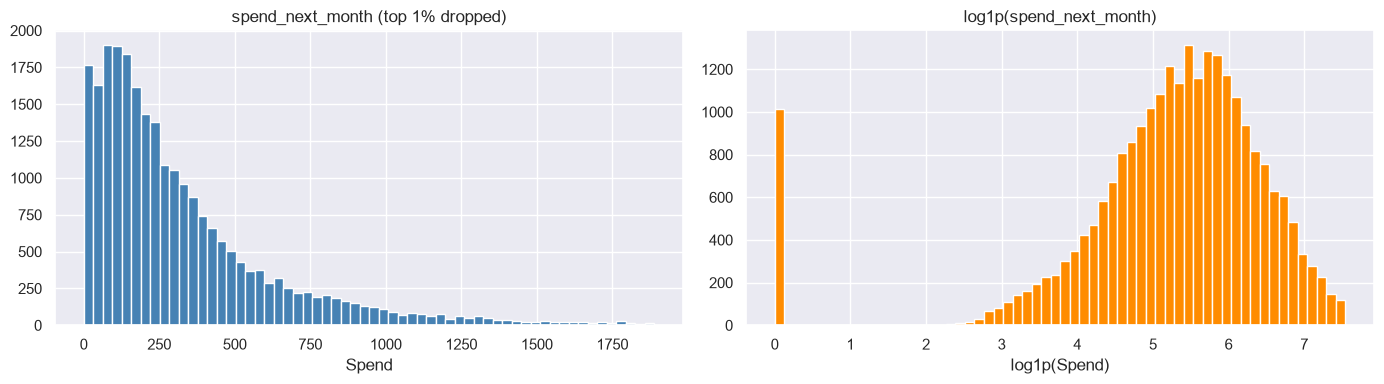

In [13]:
upper = df['spend_next_month'].quantile(0.99)
n_before = len(df)
df = df[df['spend_next_month'] <= upper].reset_index(drop=True)
print(f"99th percentile of spend_next_month : {upper:,.2f}")
print(f"Rows dropped : {n_before - len(df)}  ({(n_before - len(df)) / n_before * 100:.2f}% of data)")
print(f"Dataset now  : {df.shape}")

# Target after dropping (raw vs log scale)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['spend_next_month'].hist(bins=60, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('spend_next_month (top 1% dropped)')
axes[0].set_xlabel('Spend')

np.log1p(df['spend_next_month']).hist(bins=60, ax=axes[1], color='darkorange', edgecolor='white')
axes[1].set_title('log1p(spend_next_month)')
axes[1].set_xlabel('log1p(Spend)')

plt.tight_layout()
plt.show()

## Memory Optimisation

In [14]:
int8_cols  = ['has_children', 'email_subscribed', 'push_enabled',
              'promo_planned_next_month', 'email_data_available']
int16_cols = ['age', 'household_size', 'tenure_months', 'orders_last_1m',
              'orders_last_3m', 'orders_last_6m', 'app_sessions_30d',
              'site_visits_30d', 'wishlist_items', 'support_tickets_90d',
              'campaign_responses_6m', 'target_month', 'n_categories_6m',
              'days_since_last_purchase', 'loyalty_points',
              'snapshot_month', 'snapshot_quarter', 'snapshot_year']

for c in int8_cols:
    if c in df.columns:
        df[c] = df[c].astype('int8')
for c in int16_cols:
    if c in df.columns:
        df[c] = df[c].astype('int16')

mem_mb = df.memory_usage(deep=True).sum() / 1024**2
print(f"Memory usage : {mem_mb:.2f} MB")
print(f"Dataset shape: {df.shape}")


Memory usage : 9.96 MB
Dataset shape: (24750, 42)


## Validation

In [15]:
assert df.isnull().sum().sum() == 0,            "NaN still present!"
assert (df['spend_next_month'] >= 0).all(),     "Negative target values found!"

for ratio_col in ['return_rate', 'discount_share',
                  'email_open_rate', 'email_click_rate', 'cart_abandon_rate']:
    assert df[ratio_col].between(0, 1).all(),   f"{ratio_col} outside [0, 1]!"

for col in ['snapshot_month', 'snapshot_quarter', 'snapshot_year', 'email_data_available']:
    assert col in df.columns,                   f"Expected column '{col}' missing!"

print("All assertions passed.")
print(f"Final shape  : {df.shape}")
print(f"Columns      :\n{df.columns.tolist()}")


All assertions passed.
Final shape  : (24750, 42)
Columns      :
['age', 'gender', 'region', 'education', 'household_size', 'has_children', 'annual_income', 'tenure_months', 'membership_tier', 'preferred_channel', 'loyalty_points', 'spend_last_1m', 'spend_prev_2m', 'avg_spend_3m', 'avg_spend_6m', 'spend_trend_ratio', 'orders_last_1m', 'orders_last_3m', 'orders_last_6m', 'avg_order_value_6m', 'avg_basket_items', 'days_since_last_purchase', 'n_categories_6m', 'return_rate', 'discount_share', 'app_sessions_30d', 'site_visits_30d', 'email_subscribed', 'email_open_rate', 'email_click_rate', 'push_enabled', 'cart_abandon_rate', 'wishlist_items', 'support_tickets_90d', 'campaign_responses_6m', 'target_month', 'promo_planned_next_month', 'spend_next_month', 'snapshot_month', 'snapshot_quarter', 'snapshot_year', 'email_data_available']


## Save Cleaned Data

In [16]:
df.to_csv(OUT_PATH, index=False)
print(f"Saved  -> {OUT_PATH}")
print(f"Shape  : {df.shape}")


Saved  -> data/processed/cleaned.csv
Shape  : (24750, 42)
